# Punto 7, Parcial 2 - Introducción a la Teoría de la Computación


# Construcción de la siguiente grámatica a la Forma Normal de Chomsky (FNC)


**Gramática original** $G$:

$$
\begin{aligned}
E &\to E + T \mid T\\
T &\to T * F \mid F\\
F &\to (E) \mid a
\end{aligned}
$$

## Paso 1. El símbolo inicial no debe aparecer en el lado derecho

Como en la gramática vuelve a aparecer la misma regla E después del paso 4, no será necesario añadir un nuevo símbolo inicial.

## Paso 2. Eliminar producciones $A \to \varepsilon$

$G$ no contiene producciones vacías.

## Paso 3. Eliminar producciones unitarias $A \to B$

Producciones unitarias presentes: $E \to T$, $T \to F$.

Clausura unitaria:
$$E \Rightarrow^{*} T \Rightarrow^{*} F$$

Sustituyendo cada unitaria por las producciones no unitarias alcanzadas:

$$
\begin{aligned}
E &\to E+T \mid T*F \mid (E) \mid a\\
T &\to T*F \mid (E) \mid a\\
F &\to (E) \mid a
\end{aligned}
$$

## Pasos 4 y 5. Longitud menor que 2 y símbolos derechos como variables

Primero se aíslan los terminales en variables:

$$X_p \to {+} \qquad X_d \to {*} \qquad X_l \to ( \qquad X_r \to )$$

Luego se introducen variables auxiliares para las producciones de tres símbolos:

$$C_1 \to X_p\,T \qquad C_2 \to X_d\,T \qquad C_3 \to E\,X_r$$

Con lo cual $G$ queda:

$$
\begin{aligned}
E &\to E\,C_1 \mid T\,C_2 \mid X_l\,C_3 \mid a\\
T &\to T\,C_2 \mid X_l\,C_3 \mid a\\
F &\to X_l\,C_3 \mid a\\
C_1 &\to X_p\,T\\
C_2 &\to X_d\,F\\
C_3 &\to E\,X_r\\
X_p &\to {+}\\
X_d &\to {*}\\
X_l &\to (\\
X_r &\to )
\end{aligned}
$$

La gramática en la FNC con la estructura a conveniencia que elegimos es un objeto con la siguiente forma:

In [1]:
G = {
    "E": {("E", "C_1"), ("T", "C_2"), ("X_l", "C_3"), "a"},
    "T": {("T", "C_2"), ("X_l", "C_3"), "a"},
    "F": {("X_l", "C_3"), "a"},
    "C_1": {("X_p", "T")},
    "C_2": {("X_d", "F")},
    "C_3": {("E", "X_r")},
    "X_p": {"+"},
    "X_d": {"*"},
    "X_l": {"("},
    "X_r": {")"},
    }

# Implementación de Algoritmo CYK



El algoritmo CYK decide si una cadena $w$ pertenece al lenguaje generado por una gramática libre de contexto $G$ en **Forma Normal de Chomsky**

**Idea central:** se construye una tabla triangular $T[i][l]$ donde cada celda contiene el conjunto de no terminales que generan la subcadena de longitud $l$ que empieza en la posición $i$. La tabla se llena de abajo hacia arriba:

1. **Caso base ($l=1$):** para cada símbolo $w[i]$, se agregan a $T[i][1]$ los no terminales $A$ tales que $A \to w[i]$.
2. **Caso recursivo ($l>1$):** para cada partición de la subcadena en dos trozos de longitud $k$ y $l-k$, si $B \in T[i][k]$, $C \in T[i+k][l-k]$ y existe $A \to BC$, entonces $A \in T[i][l]$.

La cadena es aceptada si el símbolo inicial $S$ pertenece a $T[0][n]$, donde $n$ es la longitud de la cadena.

In [2]:
w = input()
n = len(w)

a+a


In [3]:
def CYK(G, w):

    T = [[set() for _ in range(n + 1)] for _ in range(n)]

    for i in range(n):
        for A, producciones in G.items():
            if w[i] in producciones:
                T[i][1].add(A)

    for l in range(2, n + 1):
        for i in range(n - l + 1):
            for k in range(1, l):

                izquierda = T[i][k]
                derecha = T[i + k][l - k]

                for B in izquierda:
                    for C in derecha:

                        for A, producciones in G.items():
                            if (B, C) in producciones:
                                T[i][l].add(A)

    return T

T = CYK(G, w)

if "E" in T[0][n]:
    print("La cadena es aceptada.")
else:
    print("La cadena NO es aceptada.")

La cadena es aceptada.


## ¿Cómo generar el árbol?

El CYK estándar únicamente guarda que se derivó. Para reconstruir un árbol de derivación hace falta memoria adicional:

1. **Registrar la regla usada, no solo el resultado.** Se añade una tabla paralela $P[i][l]$ que, por cada $A \in T[i][l]$, guarda la producción concreta que lo generó: si fue terminal ($A \to w[i]$) o binaria ($A \to BC$ con el punto de partición $k$).
2. **Reconstruir recursivamente desde la raíz.** Con $P$ poblado, se recorre desde $(0, n, S)$ hacia las hojas siguiendo los punteros guardados, construyendo una estructura de árbol (tuplas anidadas `(símbolo, [hijos])`).
3. **Convertir el árbol a un grafo dibujable.** Como símbolos como `T` o `a` se repiten en distintos nodos, cada nodo del árbol necesita un identificador único antes de pasarlo a `networkx`; de lo contrario los nodos repetidos se colapsarían en uno solo.
4. **Calcular un layout jerárquico.** `networkx` no dibuja árboles por defecto, así que se calcula la posición $(x, y)$ de cada nodo por profundidad y por promedio de posición de sus hijos (similar al algoritmo de Reingold–Tilford).

En resumen: el cambio no está en la lógica de aceptación del CYK, sino en **no descartar la información de la derivación** mientras se llena la tabla.

## Ejemplo: $w = \texttt{a+a+a}$

Indexamos los caracteres como $w_0=\texttt{a},\, w_1=\texttt{+},\, w_2=\texttt{a},\, w_3=\texttt{+},\, w_4=\texttt{a}$, con $n=5$.

### Tabla $T$ en el CYK normal

$T[i][l]$ es el conjunto de no terminales que derivan la subcadena de longitud $l$ que empieza en $i$:

| i \ l | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| 0 | {E, T, F}| — | {E} | — | {E} |
| 1 | {X_p} | {C_1} | — | — |  |
| 2 | {E, T, F} | — | {E} |  |  |
| 3 | {X_p} | {C_1} |  |  |  |
| 4 | {E, T, F} |  |  |  |  |

**Nota:** Cada celda es el conjunto $T[i][l]$; "—" indica $\varnothing$ (conjunto vacío).

Como $E \in T[0][5]$, la cadena es **aceptada**.

### Tablas $T$ y $P$ en la versión para graficar

$T$ es idéntica a la anterior. $P[i][l]$ guarda, para cada símbolo, la regla concreta que lo generó (terminal o binaria con su punto de partición $k$):

| Celda $(i,l)$ | Subcadena | $T[i][l]$ | $P[i][l]$ |
|---|---|---|---|
| $(0,1)$ | `a` | $\{E,T,F\}$ | $E,T,F \to (\text{terminal},\texttt{a})$ |
| $(1,1)$ | `+` | $\{X_p\}$ | $X_p \to (\text{terminal},\texttt{+})$ |
| $(2,1)$ | `a` | $\{E,T,F\}$ | $E,T,F \to (\text{terminal},\texttt{a})$ |
| $(3,1)$ | `+` | $\{X_p\}$ | $X_p \to (\text{terminal},\texttt{+})$ |
| $(4,1)$ | `a` | $\{E,T,F\}$ | $E,T,F \to (\text{terminal},\texttt{a})$ |
| $(1,2)$ | `+a` | $\{C_1\}$ | $C_1 \to (\text{binaria},\,k{=}1,\,X_p,\,T)$ |
| $(3,2)$ | `+a` | $\{C_1\}$ | $C_1 \to (\text{binaria},\,k{=}1,\,X_p,\,T)$ |
| $(0,3)$ | `a+a` | $\{E\}$ | $E \to (\text{binaria},\,k{=}1,\,E,\,C_1)$ |
| $(2,3)$ | `a+a` | $\{E\}$ | $E \to (\text{binaria},\,k{=}1,\,E,\,C_1)$ |
| $(0,5)$ | `a+a+a` | $\{E\}$ | $E \to (\text{binaria},\,k{=}3,\,E,\,C_1)$ |

Con estas dos entradas ($P[0][5][\texttt{"E"}]$ como raíz), `construir_arbol` desciende recursivamente hasta las hojas terminal, reconstruyendo exactamente esa asociatividad izquierda en la forma del árbol dibujado.

In [4]:
def CYK_para_graficar(G, w):

    T = [[set() for _ in range(n + 1)] for _ in range(n)]
    P = [[dict() for _ in range(n + 1)] for _ in range(n)]  # punteros para reconstrucción

    for i in range(n):
        for A, producciones in G.items():
            if w[i] in producciones:
                T[i][1].add(A)
                P[i][1].setdefault(A, []).append(("terminal", w[i]))

    for l in range(2, n + 1):
        for i in range(n - l + 1):
            for k in range(1, l):

                izquierda = T[i][k]
                derecha = T[i + k][l - k]

                for B in izquierda:
                    for C in derecha:

                        for A, producciones in G.items():
                            if (B, C) in producciones:
                                T[i][l].add(A)
                                P[i][l].setdefault(A, []).append(("binaria", k, B, C))

    return T, P

# Visualización del árbol


El siguiente código construye el árbol a partir de $P$ y lo dibuja con `networkx`. Es solo utilería de graficación, no forma parte de la teoría de CYK.

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
from itertools import count

def construir_arbol(i, l, A, P):

    opcion = P[i][l][A][0]

    if opcion[0] == "terminal":
        _, terminal = opcion
        return (A, [(terminal, [])])

    _, k, B, C = opcion
    izquierdo = construir_arbol(i, k, B, P)
    derecho = construir_arbol(i + k, l - k, C, P)
    return (A, [izquierdo, derecho])

def arbol_a_grafo(arbol):

    grafo = nx.DiGraph()
    contador = count()
    etiquetas = {}

    def recorrer(nodo, padre=None):
        simbolo, hijos = nodo
        id_nodo = next(contador)
        etiquetas[id_nodo] = simbolo
        grafo.add_node(id_nodo)
        if padre is not None:
            grafo.add_edge(padre, id_nodo)
        for hijo in hijos:
            recorrer(hijo, id_nodo)
        return id_nodo

    recorrer(arbol)
    return grafo, etiquetas


def calcular_posiciones(grafo, raiz):

    posiciones = {}
    siguiente_x = count()
    profundidad = {raiz: 0}

    def asignar_profundidad(nodo):
        for hijo in grafo.successors(nodo):
            profundidad[hijo] = profundidad[nodo] + 1
            asignar_profundidad(hijo)

    asignar_profundidad(raiz)

    def asignar_x(nodo):
        hijos = list(grafo.successors(nodo))
        if not hijos:
            x = next(siguiente_x)
        else:
            x = sum(asignar_x(hijo) for hijo in hijos) / len(hijos)
        posiciones[nodo] = (x, -profundidad[nodo])
        return x

    asignar_x(raiz)
    return posiciones


def graficar_arbol(arbol, titulo="Árbol de derivación"):
    grafo, etiquetas = arbol_a_grafo(arbol)
    posiciones = calcular_posiciones(grafo, raiz=0)

    plt.figure(figsize=(max(6, len(etiquetas) * 0.8), 6))
    nx.draw(
        grafo,
        pos=posiciones,
        labels=etiquetas,
        with_labels=True,
        node_color="#dbe9ff",
        node_size=1400,
        font_size=10,
        font_weight="bold",
        edge_color="#555555",
        arrows=False,
    )
    plt.title(titulo)
    plt.axis("off")
    plt.show()

    #Agradecimientos a Claude.

# Resultado Final

La cadena es aceptada.


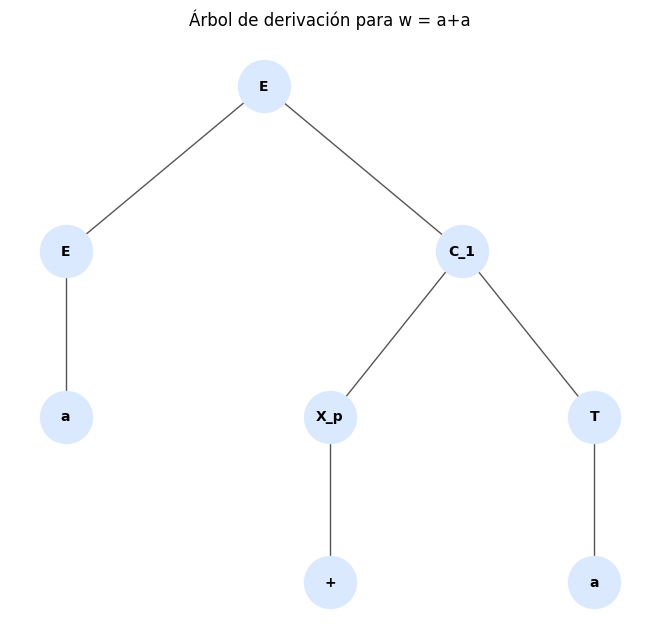

In [6]:
CYK = CYK_para_graficar(G, w)
T = CYK[0]
P = CYK[1]

if "E" in T[0][n]:
    print("La cadena es aceptada.")
    arbol = construir_arbol(0, n, "E", P)
    graficar_arbol(arbol, titulo=f"Árbol de derivación para w = {w}")
else:
    print("La cadena NO es aceptada.")

# Conclusión

Fué complicado entenderlo, pero es interesante el algoritmo, sabiendo que normalmente, para saber si una cadena es generada por una gramática sería revisando todas las derivaciones posibles a partir de E, precisamente crecería exponencialmente según la longitud de la cadena. CYK se encarga de evitar esa subida y la reduce a complejidad $O(n^3 \cdot |G|)$